# 03 · Prioritize unusual observations

**Question: with five review slots per month, do a simple rule and Isolation Forest choose different records?** A reviewer checks monthly trade aggregates, not individual transactions.

This is a statistical experiment relevant to fraud review. **There are no fraud labels, so I cannot measure fraud detection accuracy or expected losses.**

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from moto_study.decoding import GRAIN, ROUTE
from moto_study.io import load_prepared, project_root
from moto_study.plots import set_style, short_label
from moto_study.risk import (
    ALL_FEATURES,
    FEATURES,
    MIN_VALUE,
    MONTHLY_BUDGET,
    compare_review_queues,
    eligibility_reasons,
    fit_forest,
    historical_features,
)

root = project_root()
trade = load_prepared(root)
set_style()
pd.options.display.float_format = "{:,.3f}".format

## 1. Remove recurring annual patterns

For each route, I calculate `log(current / same month last year)`. I compare that change with the **previous** twelve monthly changes, requiring at least nine usable values.

The deviation is `(change − prior median) / max(1.4826 × MAD, 0.10)`. The median is the middle value; MAD measures typical distance from it. Logs make changes proportional. The floor prevents tiny historical variation from producing extreme scores.

**A perfectly repeated summer peak gets a zero deviation. Current and future observations never enter the historical reference.** This handles stable annual patterns, but changing seasonality can still be flagged.

In [2]:
features = historical_features(trade)
training = features.loc[features.eligible & features.month.le("2023-12-01")]
display(training[ALL_FEATURES].corr(method="spearman").round(2))
display(
    pd.DataFrame(
        {
            "floor used (%)": [
                100 * training[f + "_reference_scale"].lt(0.10).mean() for f in FEATURES
            ]
        },
        index=FEATURES,
    )
)

,value_z,mass_z,unit_value_z
value_z,1.000,0.920,0.100
mass_z,0.920,1.000,-0.140
unit_value_z,0.100,-0.140,1.000


,floor used (%)
mass_z,0.123
unit_value_z,26.456


**Value = mass × EUR/kg. These are linked signals, not independent evidence.** The value and mass deviations correlate at 0.92 (Spearman, training data). The table uses deviations rather than raw country sizes. I retain mass and EUR/kg for both methods; they describe volume and value per unit of weight. I keep value deviation only as a diagnostic.

The rule takes the largest absolute deviation. The forest isolates unusual combinations through random splits. Neither score is a fraud probability.

In [3]:
later = features.loc[features.month.between("2024-01-01", "2025-12-01")]
display(eligibility_reasons(later))
scored, forest, _ = fit_forest(features)  # Fit only through December 2023; 150 trees, seed 42.
ranked = compare_review_queues(scored)
review_pool = int(len(ranked))
display(
    Markdown(
        f"**Only {int(later.eligible.sum()):,}/{len(later):,} later observations are scoreable; "
        f"{review_pool:,} also meet the EUR {MIN_VALUE:,} value gate.** "
        "Short or broken histories are a major blind spot. Unscored is not low risk. "
        "Missing routes are outside this ranking and need separate coverage checks."
    )
)

,reason,observations
0,eligible,11334
1,insufficient historical reference,9046
2,current missing/nonpositive measure,416


**Only 11,334/20,796 later observations are scoreable; 10,516 also meet the EUR 10,000 value gate.** Short or broken histories are a major blind spot. Unscored is not low risk. Missing routes are outside this ranking and need separate coverage checks.

## 2. Set capacity before comparing rankings

**Each method gets five slots within each monthly batch, among eligible rows worth at least EUR 10,000.** These are illustrative capacity and materiality choices, not settings fitted to later anomalies. The gate avoids spending the demonstration's slots on tiny amounts; it can miss small-value fraud.

Rank 1 is highest. Ties use the observation key. Batches refer to trade months after data become available; this snapshot does not recreate their release dates.

In [4]:
display(ranked.queue_group.value_counts().rename("observations"))
selected = ranked.loc[ranked.queue_group.ne("neither")].copy()
assert (
    ranked.loc[ranked.forest_rank.le(ranked.slots)].groupby("month").size().eq(MONTHLY_BUDGET).all()
)
assert (
    ranked.loc[ranked.rule_rank.le(ranked.slots)].groupby("month").size().eq(MONTHLY_BUDGET).all()
)
shared = int(ranked.queue_group.eq("both").sum())
display(
    Markdown(
        f"**Each method selects 120 observations across 24 batches. They share {shared}; "
        f"each selects {120 - shared} different observations.** Agreement does not establish correctness."
    )
)

queue_group
neither        10379
both             103
forest only       17
rule only         17
Name: observations, dtype: int64

**Each method selects 120 observations across 24 batches. They share 103; each selects 17 different observations.** Agreement does not establish correctness.

## 3. Check sensitivity instead of trusting one setting

I change one setting at a time. The table counts selections replaced compared with the default five-slot queues. I do not select the settings that produce the most impressive cases.

In [5]:
def selected_keys(frame, rank):
    return set(map(tuple, frame.loc[frame[rank].le(frame.slots), GRAIN].to_numpy()))


reference = {rank: selected_keys(ranked, rank) for rank in ["forest_rank", "rule_rank"]}
changes = []
for floor, seed in [(0.05, 42), (0.20, 42), (0.10, 0), (0.10, 7), (0.10, 123)]:
    alternative = features.copy()
    for f in FEATURES:
        alternative[f] = (
            alternative[f + "_yoy_log_change"] - alternative[f + "_reference_median"]
        ) / alternative[f + "_reference_scale"].clip(lower=floor)
    alternative["robust_score"] = (
        alternative[FEATURES].abs().max(axis=1).where(alternative.eligible)
    )
    alternative_scored, _, _ = fit_forest(alternative, seed=seed)
    queue = compare_review_queues(alternative_scored)
    changes.append(
        {
            "scale floor": floor,
            "seed": seed,
            **{
                rank.replace("_rank", " replaced"): len(
                    reference[rank] - selected_keys(queue, rank)
                )
                for rank in reference
            },
        }
    )
display(pd.DataFrame(changes))
workloads = []
for capacity, gate in [(3, 10_000), (5, 0), (5, 10_000), (5, 50_000), (10, 10_000)]:
    queue = compare_review_queues(scored, budget=capacity, min_value=gate)
    a, b = selected_keys(queue, "forest_rank"), selected_keys(queue, "rule_rank")
    workloads.append(
        {
            "slots/month": capacity,
            "minimum EUR": gate,
            "each method": len(a),
            "shared": len(a & b),
            "forest default replaced": len(reference["forest_rank"] - a),
        }
    )
display(pd.DataFrame(workloads))

,scale floor,seed,forest replaced,rule replaced
0,0.050,42,17,16
1,0.200,42,35,35
2,0.100,0,9,0
3,0.100,7,6,0
4,0.100,123,6,0


,slots/month,minimum EUR,each method,shared,forest default replaced
0,3,10000,72,59,48
1,5,0,120,101,17
2,5,10000,120,103,0
3,5,50000,120,108,22
4,10,10000,240,201,0


**Doubling the floor replaces 35/120 forest selections; changing the seed replaces 6–9. The workload choices also change the queue. Borderline positions should not be treated as stable conclusions.** The rule avoids random-seed variation but still depends on the reference window, floor and value gate. Keep these assumptions visible.

## 4. Work through two disagreements

I take the first month with disagreements and inspect one case from each side. These illustrate the methods; they are not evidence that either is more accurate.

In [6]:
cases = ranked.loc[
    ranked.month.eq("2024-01-01") & ranked.queue_group.isin(["forest only", "rule only"])
]
display(cases[[*GRAIN, "queue_group", "forest_rank", "rule_rank"]])
measurements = cases[
    [
        "value_eur",
        "net_mass_kg",
        "items_reported",
        "unit_value_eur_per_kg",
        "value_eur_per_item",
        "mass_kg_per_item",
        *FEATURES,
    ]
].T
measurements.columns = ["Germany → Türkiye", "Italy → US"]
display(measurements)
# Reconstruct the rule score for Italy's exports to the US, above 500–800 cc.
case = cases.loc[cases.queue_group.eq("rule only")].iloc[0]
calculation = pd.DataFrame(
    [
        {
            "measure": f,
            "year-on-year log change": case[f + "_yoy_log_change"],
            "prior median": case[f + "_reference_median"],
            "MAD scale": case[f + "_reference_scale"],
            "usable prior changes": case[f + "_history_count"],
            "deviation": case[f],
        }
        for f in FEATURES
    ]
)
display(calculation)
assert np.isclose(case.robust_score, calculation.deviation.abs().max())

,month,reporter,partner,product,flow,queue_group,forest_rank,rule_rank
135,2024-01-01,DE,TR,87115000,2,forest only,2,7
323,2024-01-01,IT,US,87114000,2,rule only,6,3


,Germany → Türkiye,Italy → US
value_eur,"4,940,302.000","20,010,376.000"
net_mass_kg,"94,568.000","84,193.000"
items_reported,399.000,643.000
unit_value_eur_per_kg,52.241,237.673
value_eur_per_item,"12,381.709","31,120.336"
mass_kg_per_item,237.013,130.938
mass_z,8.176,0.859
unit_value_z,-6.188,10.090


,measure,year-on-year log change,prior median,MAD scale,usable prior changes,deviation
0,mass_z,0.846,0.203,0.748,12.000,0.859
1,unit_value_z,1.840,0.145,0.168,12.000,10.090


In [7]:
comparisons = []
for _, case in cases.iterrows():
    dates = pd.to_datetime(["2023-01-01", "2023-12-01", "2024-01-01"])
    route = trade.loc[trade[ROUTE].eq(case[ROUTE]).all(axis=1) & trade.month.isin(dates)]
    comparisons.append(route.assign(route=case.reporter + " → " + case.partner))
display(
    pd.concat(comparisons)[
        ["route", "month", "net_mass_kg", "items_reported", "unit_value_eur_per_kg"]
    ]
)

,route,month,net_mass_kg,items_reported,unit_value_eur_per_kg
51254,DE → TR,2023-01-01,437.000,1.000,97.597
60703,DE → TR,2023-12-01,"71,302.000",300.000,58.032
61470,DE → TR,2024-01-01,"94,568.000",399.000,52.241
51620,IT → US,2023-01-01,"36,146.000",175.000,37.750
61076,IT → US,2023-12-01,"9,492.000",52.000,74.804
61823,IT → US,2024-01-01,"84,193.000",643.000,237.673


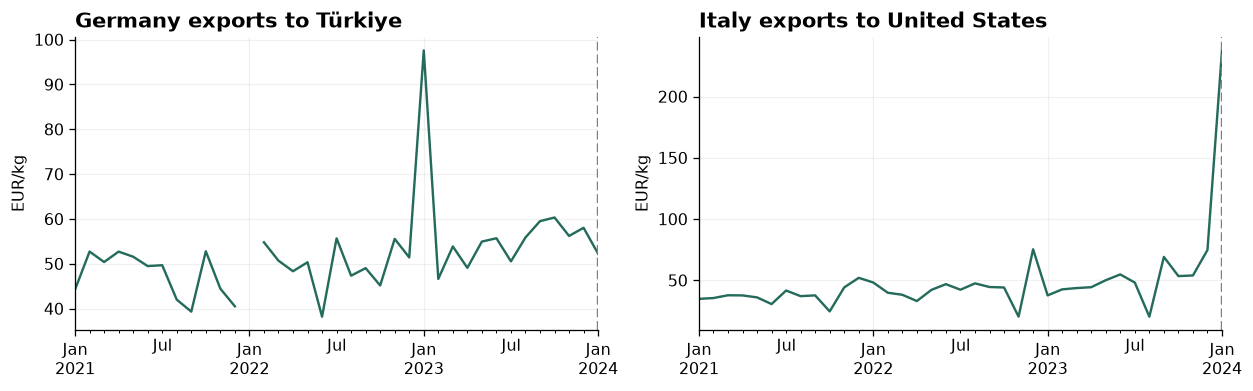

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, (_, case) in zip(axes, cases.iterrows()):
    route = trade.loc[trade[ROUTE].eq(case[ROUTE]).all(axis=1)].set_index("month").sort_index()
    dates = pd.date_range("2021-01-01", case.month, freq="MS")
    route.reindex(dates).unit_value_eur_per_kg.plot(ax=ax)
    direction = "imports from" if case.flow == "1" else "exports to"
    ax.set(
        title=f"{short_label(case.reporter_label)} {direction} {short_label(case.partner_label)}",
        ylabel="EUR/kg",
        xlabel="",
    )
    ax.axvline(case.month, color="grey", linestyle="--")
plt.tight_layout()
plt.show()
selected.to_csv(root / "data/processed/review_queue.csv", index=False)

- **Germany's exports to Türkiye: forest rank 2, rule rank 7.** Mass rises from 437 kg a year earlier to 94,568 kg. **The huge annual change starts from a very small comparison month.** I would check that earlier month first.
- **Italy's exports to the US: rule rank 3, forest rank 6.** EUR/item rises from 7,797 to 31,120 while kg/item falls from 206.5 to 130.9. I would check valuation, quantity and product mix together.

**A year-on-year score can flag a rebound from an unusual prior year. It does not necessarily mean the current level is abnormal. The largest rule deviation also does not explain the forest's decision.** I would verify weight, item count and valuation against supporting records before interpreting either case.

**Decision: keep the rule as the transparent reference and the forest as a comparison.** Choosing a policy needs independent reviews of shared, differing and unselected cases. This experiment shows workload and trade-offs, not fraud performance. Next: [an assistant for the evidence checks](04_review_assistant.ipynb).